# Interactive mesh viewer

The Python script owns the parameters, geometry, mesh generation, and simulations. Run `single_hole_test.py` first; it exports the mesh to `results/meshes/mesh_hole.h5`. This notebook only loads that mesh file for visualization and does not rebuild the geometry or call `tdgl.solve`.

The model uses micrometres: the strip is 0.2 um wide by 2 um long and the hole is 0.100 um (100 nm) in diameter. Use the Matplotlib toolbar to zoom and pan.

In [7]:
%matplotlib widget

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import tdgl

plt.rcParams["figure.figsize"] = (8, 10)
plt.rcParams["figure.dpi"] = 120

## Load the mesh exported by the simulation script

In [8]:
mesh_file = Path.cwd() / "results" / "meshes" / "mesh_hole.h5"
if not mesh_file.exists():
    mesh_file = Path("/home/afons/Thesis/results/meshes/mesh_hole.h5")
if not mesh_file.exists():
    raise FileNotFoundError(
        f"Mesh not found: {mesh_file}. Run single_hole_test.py first."
    )

device = tdgl.Device.from_hdf5(str(mesh_file))
print(f"Loaded mesh: {mesh_file}")

Loaded mesh: /home/afons/Thesis/results/meshes/mesh_hole.h5


In [9]:
print(device.mesh_stats())

<IPython.core.display.HTML object>


## Mesh quality checks

These checks test the actual saved mesh. The Voronoi warnings printed by pyTDGL concern a few boundary control-volume constructions; they are not, by themselves, proof that the triangular mesh is invalid.

In [10]:
points = np.asarray(device.points)
triangles = np.asarray(device.triangles)
edge_lengths = np.asarray(device.edge_lengths)
cell_areas = np.asarray(device.areas)

print(f"sites: {len(points):,}")
print(f"triangles: {len(triangles):,}")
print(f"edge length range: {edge_lengths.min():.6f} to {edge_lengths.max():.6f} um")
print(f"cell area range: {cell_areas.min():.6e} to {cell_areas.max():.6e} um^2")
print(f"non-finite values: {np.count_nonzero(~np.isfinite(points)) + np.count_nonzero(~np.isfinite(edge_lengths)) + np.count_nonzero(~np.isfinite(cell_areas))}")
print(f"non-positive edges: {np.count_nonzero(edge_lengths <= 0)}")
print(f"non-positive cell areas: {np.count_nonzero(cell_areas <= 0)}")

sites: 3,053
triangles: 5,308
edge length range: 0.001143 to 0.050949 um
cell area range: 7.586604e-07 to 1.525787e-03 um^2
non-finite values: 0
non-positive edges: 0
non-positive cell areas: 0


## Full mesh

The toolbar magnifying glass zooms into a rectangle. The pan tool moves the view after zooming.

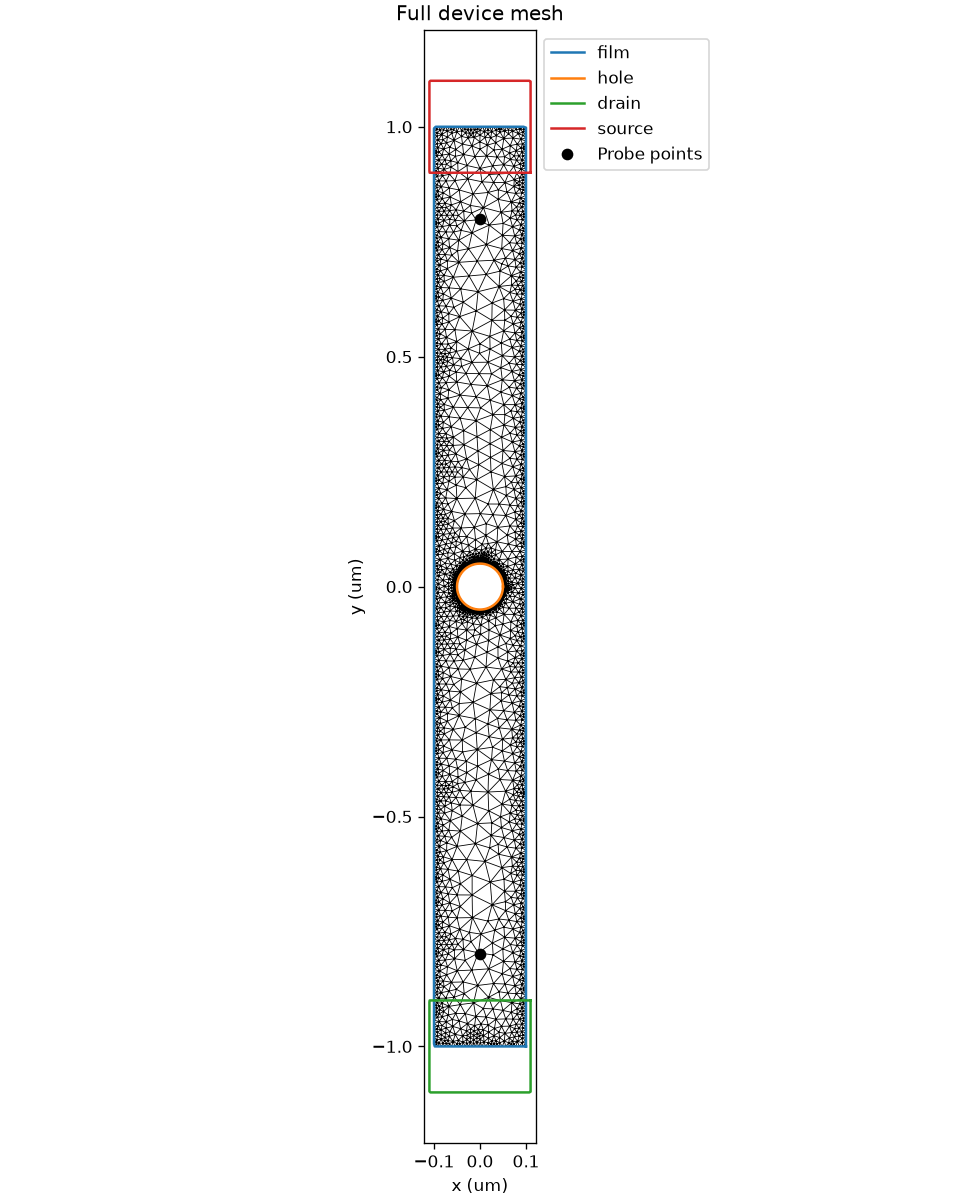

In [11]:
fig, ax = device.plot(mesh=True)
ax.set_aspect("equal")
ax.set_title("Full device mesh")
ax.set_xlabel("x (um)")
ax.set_ylabel("y (um)")
plt.show()

## Hole close-up

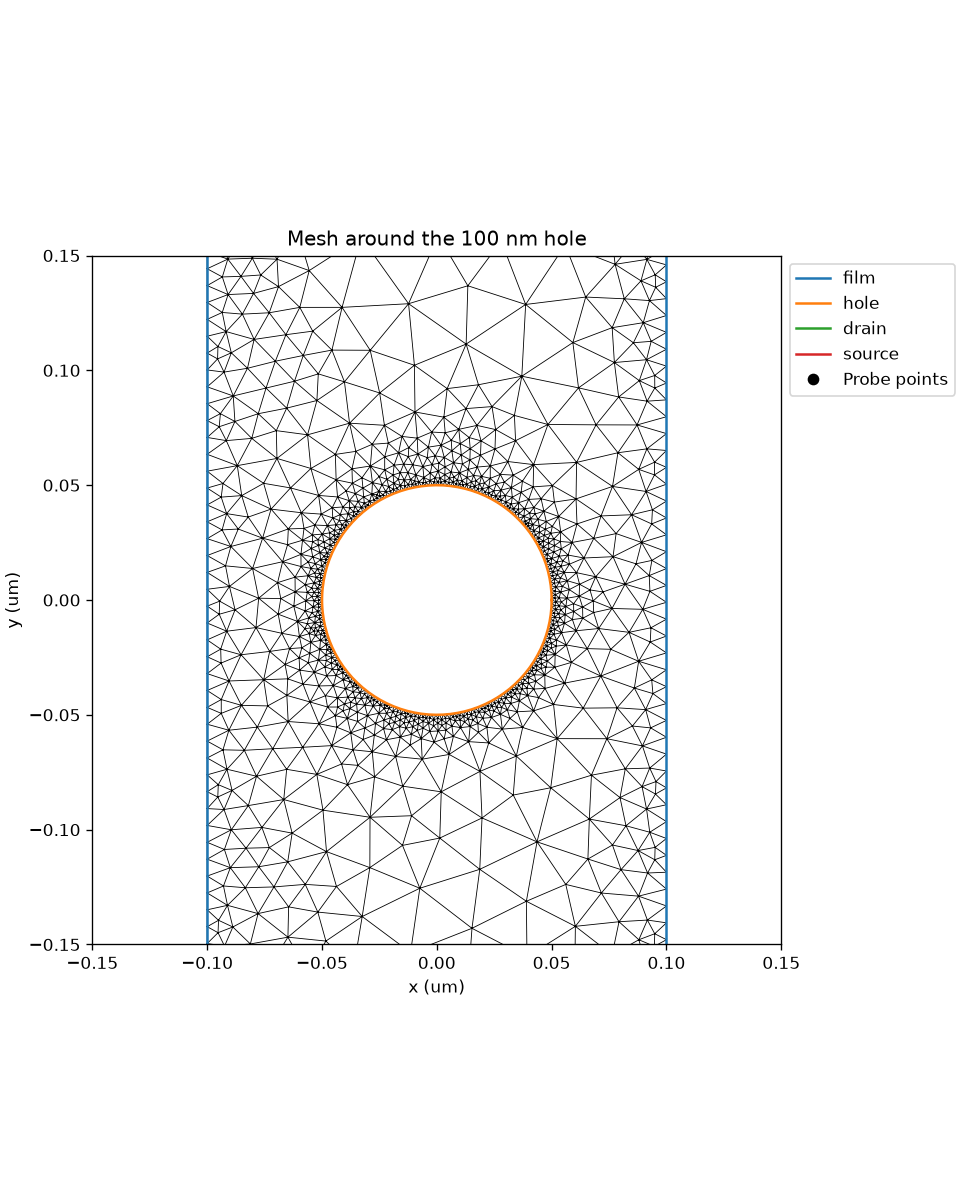

In [12]:
fig_close, ax_close = device.plot(mesh=True)
ax_close.set_aspect("equal")
window = 0.15
ax_close.set_xlim(-window, window)
ax_close.set_ylim(-window, window)
ax_close.set_title("Mesh around the 100 nm hole")
ax_close.set_xlabel("x (um)")
ax_close.set_ylabel("y (um)")
plt.show()